# 01 · Data and bigram language model

**Goal.** Build the initial language model that policy gradient will later fine-tune: a word bigram
$P_{\text{bigram}}(w \mid u)$ over a small vocabulary whose words all have a known syllable count.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from poet import corpus, bigram

SEED = 0
BOOK_DIR = Path('..') / 'data' / 'books'
VOCAB_SIZE = 500
plt.rcParams['figure.dpi'] = 110

## 1. Corpus

Three Project Gutenberg books in `data/books/`: the Odyssey, the Iliad and
Beowulf. `corpus.load_book` keeps only the poem itself:

1. the text between the Gutenberg `*** START` / `*** END` markers;
2. inside it, only the span from the poem's first heading to the start of the back matter (`corpus.BOOKS`,
   matched on the Gutenberg `Title:` line). This removes the different kind of introductions;
3. book-specific apparatus inside the poem: the Iliad's prose argument summary at the head of each book, and
   Hall's Beowulf footnotes (lines indented by exactly 4 spaces, while verse lines are indented by 5 or more);
4. generic cleaning: bracketed material (footnote markers, illustration captions), braced marginal glosses in
   Beowulf (`{Scyld dies at the hour appointed by Fate.}`), all-caps headings, typographic quotes, and
   ligatures/accents (*phœbus* → *phoebus*, *belovèd* → *beloved*).

Sentences are split on `. ? ! ; :`. Line breaks are ignored, because in verse a line is not a sentence.

In [ ]:
books = sorted(BOOK_DIR.glob('*.txt'))                                     
per_book = {}
for path in books:
    s = corpus.tokenize_sentences(corpus.load_book(path))
    per_book[path.stem] = s
    n_tok = sum(len(x) for x in s)
    print(f'{path.stem:16s} sentences={len(s):6d}  tokens={n_tok:7d}  mean sentence length={n_tok/len(s):5.1f}')

sentences = corpus.load_corpus(BOOK_DIR)
counts = corpus.count_words(sentences)
print(f'\nTOTAL            sentences={len(sentences):6d}  tokens={counts.total():7d}  distinct words={len(counts)}')

beowulf_book     sentences=  1324  tokens=  25725  mean sentence length= 19.4


homer_book       sentences= 11860  tokens= 146806  mean sentence length= 12.4
odyssey_book     sentences=  3506  tokens=  83841  mean sentence length= 23.9



TOTAL            sentences= 16690  tokens= 256372  distinct words=13101


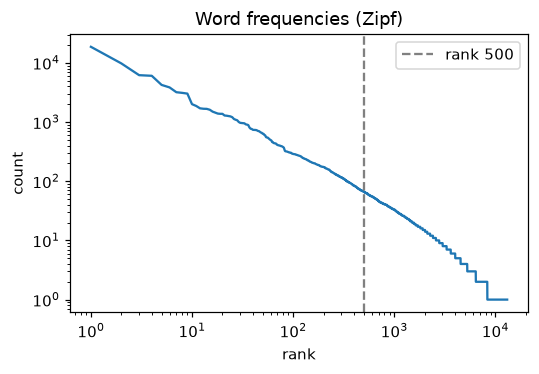

In [ ]:
freq = np.array(sorted(counts.values(), reverse=True))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.loglog(np.arange(1, len(freq) + 1), freq)
ax.axvline(VOCAB_SIZE, ls='--', c='gray', label=f'rank {VOCAB_SIZE}')
ax.set_xlabel('rank'); ax.set_ylabel('count'); ax.set_title('Word frequencies (Zipf)')
ax.legend(); plt.tight_layout(); plt.show()

## 2. Vocabulary and syllables

Vocabulary = the 500 most frequent corpus words that are in the CMU Pronouncing Dictionary
**and have at least one syllable**. Syllables are counted on the *first* pronunciation, as the number of
phonemes that end in a stress digit (vowels carry a stress mark 0/1/2 in CMUdict).

In [5]:
cmu = corpus.load_cmu_dict()
vocab = corpus.build_vocabulary(counts, cmu, VOCAB_SIZE)
syl = np.array([corpus.syllables(w, cmu) for w in vocab])

print('first 40 words:', ' '.join(vocab[:40]))
print('last 20 words :', ' '.join(vocab[-20:]))
print(f'\ntoken coverage of the {len(vocab)}-word vocabulary: {corpus.coverage(counts, vocab):.1%}')

skipped = [w for w, _ in counts.most_common() if w not in cmu][:25]
print('\nmost frequent words NOT in CMUdict (excluded):', ', '.join(skipped))

first 40 words: the and of to his in with he a i on from that for as all you but him my their they then was her it by not this thy at so when had me is who now or them
last 20 words : view brazen die distant equal gates late ranks replied save waters armour attend form mars native penelope below fires foot

token coverage of the 500-word vocabulary: 68.4%

most frequent words NOT in CMUdict (excluded): jove, o'er, telemachus, patroclus, coursers, atrides, jove's, fix'd, godlike, tydides, honours, crown'd, ilion, press'd, alcinous, pass'd, peleus, stretch'd, beauteous, achaeans, neath, turn'd, hrothgar, troy's, roll'd


In [ ]:
checks = {'the': 1, 'water': 2, 'beautiful': 3, 'ulysses': 3, 'warrior': 3,
          'achilles': 3, 'every': 3, 'morning': 2, 'fire': 1, 'heaven': 2}
for w, expected in checks.items():
    got = corpus.syllables(w, cmu)
    print(f'{w:10s} {" ".join(cmu[w][0]):28s} -> {got}  (expected {expected}){"" if got == expected else "   <-- mismatch"}')

the        DH AH0                       -> 1  (expected 1)
water      W AO1 T ER0                  -> 2  (expected 2)
beautiful  B Y UW1 T AH0 F AH0 L        -> 3  (expected 3)
ulysses    Y UW0 L IH1 S IY0 Z          -> 3  (expected 3)
warrior    W AO1 R IY0 ER0              -> 3  (expected 3)
achilles   AH0 K IH1 L IY0 Z            -> 3  (expected 3)
every      EH1 V ER0 IY0                -> 3  (expected 3)
morning    M AO1 R N IH0 NG             -> 2  (expected 2)
fire       F AY1 ER0                    -> 2  (expected 1)   <-- mismatch
heaven     HH EH1 V AH0 N               -> 2  (expected 2)


The one mismatch is a matter of pronunciation, not a bug. CMUdict's first pronunciation of *fire* is
`F AY1 ER0`, i.e. 2 syllables. We always count the first pronunciation,
so the count is deterministic.

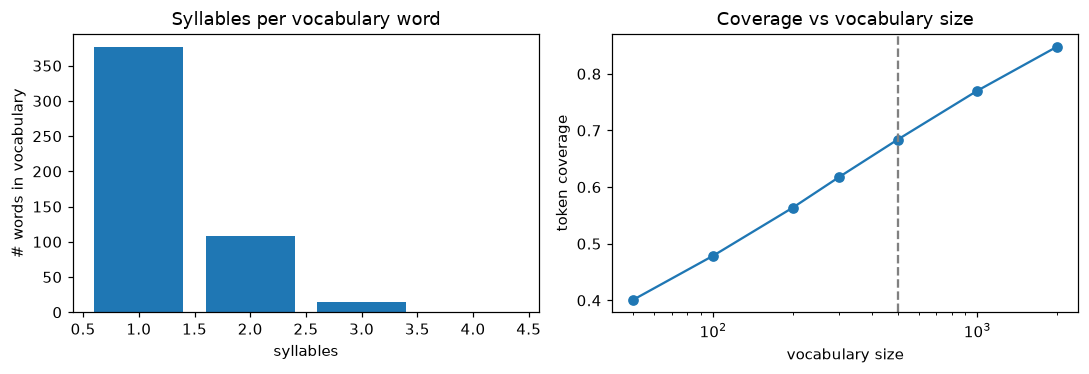

1 syllable(s): 376 words, e.g. the, and, of, to, his, in, with, he
2 syllable(s): 108 words, e.g. our, heaven, hector, before, about, father, upon, trojan
3 syllable(s): 15 words, e.g. ulysses, achilles, every, minerva, warrior, immortal, another, generous
4 syllable(s): 1 words, e.g. penelope


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
vals, cnts = np.unique(syl, return_counts=True)
axes[0].bar(vals, cnts)
axes[0].set_xlabel('syllables'); axes[0].set_ylabel('# words in vocabulary'); axes[0].set_title('Syllables per vocabulary word')

sizes = [50, 100, 200, 300, 500, 1000, 2000]
cov = [corpus.coverage(counts, corpus.build_vocabulary(counts, cmu, n)) for n in sizes]
axes[1].plot(sizes, cov, 'o-'); axes[1].set_xscale('log')
axes[1].axvline(VOCAB_SIZE, ls='--', c='gray')
axes[1].set_xlabel('vocabulary size'); axes[1].set_ylabel('token coverage'); axes[1].set_title('Coverage vs vocabulary size')
plt.tight_layout(); plt.show()
for v, c in zip(vals, cnts):
    print(f'{v} syllable(s): {c} words, e.g. {", ".join([w for w, s in zip(vocab, syl) if s == v][:8])}')

## 3. Bigram with add-$k$ smoothing

Tokens: the $V=500$ words, the start token `<s>` (a context only) and the end token `</s>`. In the MDP,
`</s>` doubles as the *end-of-line* action. The bigram is one $(V{+}1)\times(V{+}1)$ matrix

$$P_{\text{bigram}}(w \mid u) = \frac{C(u,w) + k}{\sum_{w'} C(u,w') + k\,(V+1)}$$

Bigrams that touch an out-of-vocabulary word are dropped. We do **not** glue together words that were
separated by an OOV word. Every entry is $>0$, so $\log P_{\text{bigram}}$ is finite. This matters because
the policy is initialised at $\theta=\tau\log P_{\text{bigram}}$ and the fluency reward is $\lambda\log P_{\text{bigram}}$.

**Choosing $k$:** hold out 10% of the sentences and pick the $k$ with the lowest held-out perplexity.

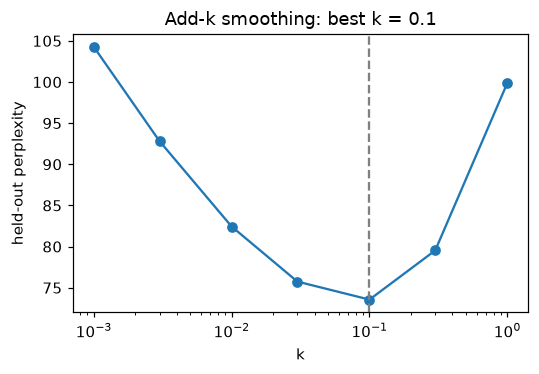

k=0.001  perplexity= 104.3
k=0.003  perplexity=  92.8
k=0.01   perplexity=  82.4
k=0.03   perplexity=  75.7
k=0.1    perplexity=  73.6
k=0.3    perplexity=  79.5
k=1.0    perplexity=  99.9
(uniform model over V+1 tokens would have perplexity 501)


In [8]:
k_grid = bigram.K_GRID
best_k, ppl = bigram.select_k(sentences, vocab, k_grid, np.random.default_rng(SEED))
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogx(k_grid, ppl, 'o-'); ax.axvline(best_k, ls='--', c='gray')
ax.set_xlabel('k'); ax.set_ylabel('held-out perplexity'); ax.set_title(f'Add-k smoothing: best k = {best_k}')
plt.tight_layout(); plt.show()
for k, p in zip(k_grid, ppl):
    print(f'k={k:<6} perplexity={p:6.1f}')
print(f'(uniform model over V+1 tokens would have perplexity {len(vocab)+1})')

In [ ]:
lm = bigram.build_bigram(BOOK_DIR, VOCAB_SIZE, seed=SEED)   
C = bigram.count_bigrams(sentences, vocab)
assert lm.vocab == vocab and lm.k == best_k
assert np.allclose(lm.P.sum(axis=1), 1) and (lm.P > 0).all()

print(f'k = {lm.k},  observed (non-zero) bigram cells: {(C > 0).mean():.1%} of {(lm.V+1)**2}')
print(f'counted in-vocabulary bigrams: {int(C.sum())}')
print(f'mass given to unseen bigrams in a typical row (median): '
      f'{np.median([lm.P[u][C[u] == 0].sum() for u in range(lm.V + 1)]):.1%}')
print(f'P(</s> | <s>) = {lm.P[lm.BOS, lm.EOS]:.2e}   (empty sentence)')

k = 0.1,  observed (non-zero) bigram cells: 10.2% of 251001
counted in-vocabulary bigrams: 130911
mass given to unseen bigrams in a typical row (median): 29.9%
P(</s> | <s>) = 7.14e-06   (empty sentence)


In [10]:
def top_next(word, n=8):
    u = lm.BOS if word == '<s>' else vocab.index(word)
    idx = np.argsort(-lm.P[u])[:n]
    return ', '.join(f'{lm.words([i])[0]} {lm.P[u, i]:.2f}' for i in idx)

for w in ['<s>', 'the', 'ulysses', 'sea', 'son', 'and']:
    print(f'{w:8s} -> {top_next(w)}')
print('("/" is </s>)')

<s>      -> the 0.11, then 0.05, and 0.04, but 0.04, he 0.04, i 0.03, so 0.02, to 0.02
the      -> gods 0.02, ground 0.02, plain 0.02, house 0.02, field 0.02, trojan 0.02, war 0.02, king 0.02
ulysses  -> and 0.07, / 0.06, was 0.04, to 0.04, said 0.04, who 0.03, answered 0.03, is 0.03
sea      -> / 0.13, and 0.12, shore 0.09, with 0.04, again 0.02, god 0.02, but 0.02, going 0.02
son      -> of 0.34, / 0.17, and 0.05, the 0.03, to 0.02, she 0.02, in 0.02, is 0.01
and      -> the 0.10, his 0.03, all 0.02, i 0.02, in 0.02, with 0.02, now 0.02, thus 0.02
("/" is </s>)


In [11]:
rng = np.random.default_rng(SEED)
print('Sentences sampled from the bigram:\n')
for _ in range(12):
    print(' ', ' '.join(lm.words(bigram.sample_sentence(lm.P, rng))))

Sentences sampled from the bigram:

  she is the son oh
  now o friend
  long the dart and even he led let her father and his friends make up his fires
  are vain
  but with fell into the suitors
  fear no such i must have no combat for she was above glorious arms
  the other with it friend with the bold by the grecian foe
  his father's than with every grace ulysses
  then they heard
  tis can get blood till again let us am raised his face
  stay and young
  alone with clouds whether immortal race with dust


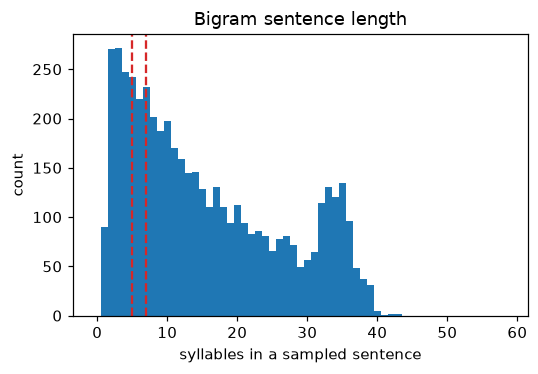

mean 15.5 syllables; P(exactly 5) = 0.048, P(exactly 7) = 0.046
naive chance that three independent sentences are 5-7-5: 1.1e-04


In [ ]:
rng = np.random.default_rng(SEED)
lens = np.array([lm.syllables[bigram.sample_sentence(lm.P, rng)].sum() for _ in range(5000)])
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(lens, bins=np.arange(0, 60) - 0.5)
for v in (5, 7): ax.axvline(v, c='C3', ls='--')
ax.set_xlabel('syllables in a sampled sentence'); ax.set_ylabel('count'); ax.set_title('Bigram sentence length')
plt.tight_layout(); plt.show()
print(f'mean {lens.mean():.1f} syllables; P(exactly 5) = {(lens == 5).mean():.3f}, P(exactly 7) = {(lens == 7).mean():.3f}')
print(f'naive chance that three independent sentences are 5-7-5: {(lens == 5).mean()**2 * (lens == 7).mean():.1e}')

## 4. Discussion

- **Corpus.** Only the poems themselves: the Odyssey (Butler, prose), the Iliad (Pope, verse) and Beowulf (Hall, verse),
  about 256k tokens, of which the Iliad is the largest part. Their archaic register gives words like *thy*, *thus* and *shall*,
  and some proper names (*ulysses*, *achilles*, *hector*, *penelope*). No word of the editors' apparatus is left.
- **Vocabulary.** 500 words cover 68% of all tokens. The frequent words missing from CMUdict are
  mostly Greek/Old English names (*jove*, *telemachus*, *patroclus*, *hrothgar*) and Pope's poetic elisions (*o'er*, *fix'd*);
  they are skipped. Three quarters of the vocabulary (376 words) is monosyllabic, which matters later: padding a
  line with short function words is an easy way to hit a syllable target (reward hacking, notebook 03). Every vocabulary word has $\ge 1$ syllable, so every word
  action advances the line, and an episode always terminates.
- **Smoothing.** Held-out perplexity is minimised at $k=0.1$ (perplexity ≈ 74, against 501 for a uniform model). Smaller $k$ over-trusts unseen
  pairs being impossible, larger $k$ flattens every row towards uniform. Only 10% of bigram cells are ever
  observed, and a typical smoothed row puts ~30% of its mass on unseen bigrams, which is where the "word salad" in the samples comes from.
- **Starting point for RL.** The bigram knows nothing about syllables. Its sentences rarely have exactly 5 or 7
  syllables (≈5% each), so three in a row of the right lengths has probability of order $10^{-4}$. This is why the haiku goal is
  **sparse** for the untrained model, and why notebook 03 designs a shaped reward and an enriched state.